# Ray-traced wireless channels

Adapted from NVIDIA’s [Sionna, v2.2.0](https://nvlabs.github.io/sionna/index.html).

## Basics and imports

Ray tracing is a technique to simulate environment-specific and physically accurate channel realizations for a given scene and user position.

Sionna RT is a open-source hardware-accelerated differentiable ray tracer for radio propagation modeling which is built on top of [Mitsuba 3](https://www.mitsuba-renderer.org/). Mitsuba 3 is a rendering system for forward and inverse light-transport simulation that makes use of the differentiable just-in-time compiler [Dr.Jit](https://drjit.readthedocs.io/en/latest/).

Sionna RT relies on Mitsuba 3 for the rendering and handling of scenes, e.g., its XML-file format.
When imported, Sionna RT automatically configures the correct [Mitsuba variant](https://mitsuba.readthedocs.io/en/stable/src/key_topics/variants.html) based on the available hardware.

In [29]:
# Import sionna and some of its relevant components
import sionna.rt
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera, PathSolver

# Import packages for this notebook to work
%matplotlib inline
import matplotlib.pyplot as plt
import mitsuba as mi
import numpy as np
from pathlib import Path

no_preview = False # Toggle to False to use the preview widget

# Query the Mitsuba variant that was automatically selected by Sionna RT.
# There should be no need to adjust it, but if you do, make sure to select
# a variant ending in `*_ad_mono_polarized`.
print(f"Mitsuba variant: {mi.variant()}")

Mitsuba variant: cuda_ad_mono_polarized


## Loading and Visualizing Scenes

Sionna RT can either load external scene files (in Mitsuba's XML file format) or it can load one of the [integrated scenes](https://nvlabs.github.io/sionna/rt/api/scene.html#examples).

In this example, we load an example scene containing central Florence, Italy.

In [30]:
# Load the integrated Florence scene
carrier_frequency = 3e9  # Hz
scene_florence = load_scene(sionna.rt.scene.florence, merge_shapes=True)
scene_florence.frequency = carrier_frequency

To visualize the scene, we can use the `preview` function which opens an interactive preview of the scene.
This only works in Jupyter notebooks.

You can use the following controls:

- Mouse left: Rotate
- Scroll wheel: Zoom
- Mouse right: Move
- Alt+Click: select a point to retrieve coordinates

Please note that only one preview instance per scene can be opened at the same time.
However, multiple scenes can be loaded in parallel.

In [31]:
if not no_preview:
    scene_florence.preview();

It is often convenient to choose a viewpoint in the 3D preview prior to rendering it as a high-quality image.
The next cell uses the "preview" camera which corresponds to the viewpoint of the current preview image.

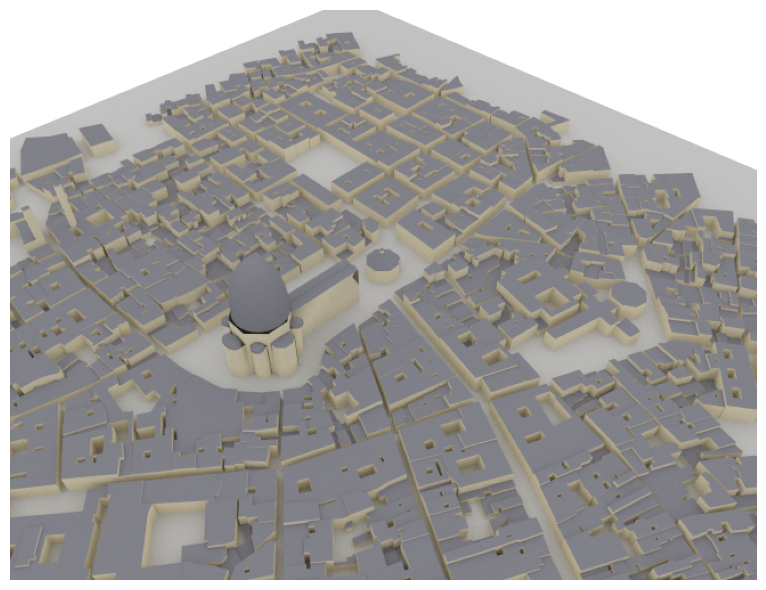

In [32]:
# Only available if a preview is open
if not no_preview:
    scene_florence.render(camera="preview", num_samples=512);

Instead of the preview camera, one can also specify dedicated cameras with different positions and `look_at` directions.

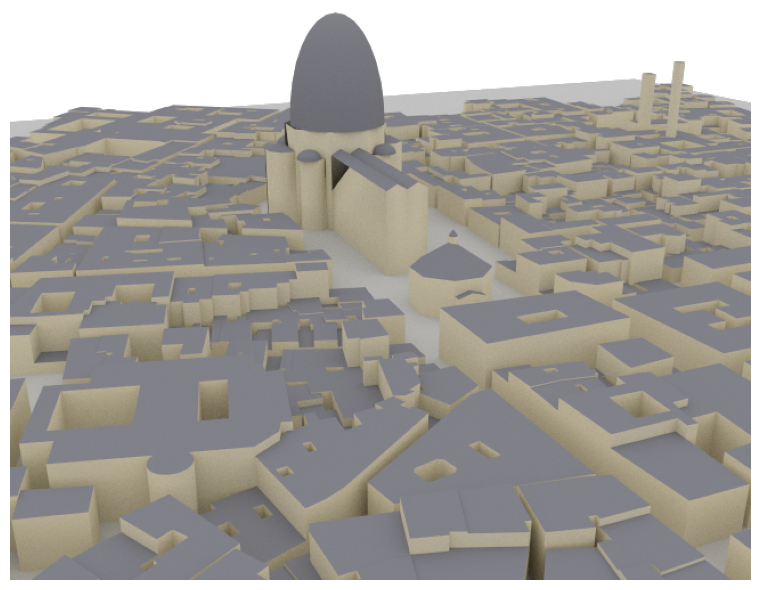

In [33]:
# Create new camera with different configuration
my_cam = Camera(position=[-350,150,150], look_at=[0,0,0])

# Render scene_florence with new camera*
scene_florence.render(camera=my_cam, resolution=[650, 500], num_samples=512); # Increase num_samples to increase image quality

### Let us try to load a custom Pisa scene

Scene files for Mitsuba 3 can be created, edited, and exported with the popular open-source 3D creation suite [Blender](https://www.blender.org/) and the [Mitsuba-Blender add-on](https://github.com/mitsuba-renderer/mitsuba-blender). One can rapdily create scenes from almost any place in the world using [OpenStreetMap](https://www.openstreetmap.org/) and the [Blender-OSM add-on](https://prochitecture.gumroad.com/l/blender-osm). In Sionna, scenes and radio propagation paths can be either rendered through the lens of configurable cameras via ray tracing or displayed with an integrated 3D viewer. For more detail on scene creation and rendering, we refer to [Sionna RT's API documentation](https://nvlabs.github.io/sionna/rt/api/rt.html) and the available [video tutorial](https://youtu.be/7xHLDxUaQ7c).

Set `pisa_scene_file` to the XML file exported from Blender/Mitsuba that is in `scenes` subfolder. Then, write the small piece of code below to preview the Pisa scene, move the camera in a desired position and render the image.

In [34]:
pisa_scene_file = None
scene_pisa = None
if pisa_scene_file is not None:
    pisa_scene_file = Path(pisa_scene_file)
    if not pisa_scene_file.is_file():
        raise FileNotFoundError(pisa_scene_file)
    scene_pisa = load_scene(str(pisa_scene_file), merge_shapes=True)
    scene_pisa.frequency = carrier_frequency
else:
    print("Pisa scene not configured; continuing with Florence.")

Pisa scene not configured; continuing with Florence.


## Ray tracing of Propagation Paths

Once a scene is loaded, we can place Transmitters and Receivers in it and compute propagation paths between them.
All transmitters and all receivers are equipped with the same antenna arrays which are defined by the scene properties `scene_florence.tx_array` and `scene_florence.rx_array`, respectively. Antenna arrays are composed of multiple identical antennas. Antennas can have custom or pre-defined patterns and are either single- or dual-polarized. A scene can contain multiple transmitters and receivers as long as they have unique names.

More details on antenna patterns can be found in the Developer Guide [Understanding Radio Materials](https://nvlabs.github.io/sionna/rt/developer/dev_custom_radio_materials.html).

In [35]:
# Configure the Florence link (coordinates in metres).
# Configure antenna array for all transmitters
scene_florence.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="V")

# Configure antenna array for all receivers
scene_florence.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="dipole",
                             polarization="V")

# Create transmitter
tx = Transmitter(name="tx",
                 position=[-22,-23,35],
                 display_radius=2)

# Add transmitter instance to scene_florence
scene_florence.add(tx)

# Create a receiver
rx = Receiver(name="rx",
              position=[44,-2,1.5],
              display_radius=2)

# Add receiver instance to scene_florence
scene_florence.add(rx)

tx.look_at(rx) # Transmitter points towards receiver

Propagation paths are computed with the help of a [PathSolver](https://nvlabs.github.io/sionna/rt/api/paths_solvers.html).
The next cell shows how such a path solver is instantiated and used. 

The parameter `max_depth` determines the maximum number of interactions between a ray and a scene objects. 
For example, with a `max_depth` of zero, only LoS paths are considered. For a `max_depth` of one, LoS as well as first-order reflections of refractions are considered.  When the argument `synthetic_array` is set to `False`, antenna arrays are explicitly modeled by finding paths between any pair of transmitting and receiving antennas in the scene. Otherwise, arrays are represented by a single antenna located in the center of the array and phase shifts related to the relative antenna positions are applied based on a plane-wave assumption.

In [44]:
# Instantiate a path solver
# The same path solver can be used with multiple scenes
p_solver  = PathSolver()

# Compute propagation paths
paths = p_solver(scene=scene_florence,
                 max_depth=5,
                 los=True,
                 specular_reflection=True,
                 diffuse_reflection=False,
                 refraction=True,
                 synthetic_array=False,
                 seed=41)

The [Paths](https://nvlabs.github.io/sionna/rt/paths.html) object contains all paths that have been found between transmitters and receivers.
In principle, the existence of each path is deterministic for a given position and environment. By default, however, `PathSolver` does not guarantee deterministic results, even when `seed` is fixed. Use `PathSolver(deterministic=True)` when deterministic results are required.

Let us now visualize the found paths in the scene:

In [45]:
if no_preview:
    scene_florence.render(camera=my_cam, paths=paths, clip_at=100);
else:
    scene_florence.preview(paths=paths, clip_at=100);

The Paths object contains detailed information about every found path and allows us to generate channel impulse responses and apply Doppler shifts for the simulation of time evolution.

### Trace the custom Pisa scene

The same `p_solver` instance can trace a different scene. Fill in the following code setting tx and rx arrays, position of transmitter and receiver and generate the paths as `paths_pisa`. Visualize the scene.

In [38]:
paths_pisa = None
pisa_tx_position = None  # TODO: [x, y, z] in metres in the custom scene
pisa_rx_position = None  # TODO: [x, y, z] in metres in the custom scene

if scene_pisa is None:
    print("Skipping Pisa ray tracing: load the custom scene first.")
elif pisa_tx_position is None or pisa_rx_position is None:
    print("Set pisa_tx_position and pisa_rx_position, then rerun this cell.")
else:
    scene_pisa.tx_array = PlanarArray(num_rows=1, num_cols=1,
        vertical_spacing=0.5, horizontal_spacing=0.5,
        pattern="tr38901", polarization="V")
    scene_pisa.rx_array = PlanarArray(num_rows=1, num_cols=1,
        vertical_spacing=0.5, horizontal_spacing=0.5,
        pattern="dipole", polarization="cross")
    # Re-running this cell replaces the previously configured devices.
    scene_pisa.remove("tx")
    scene_pisa.remove("rx")
    tx_pisa = Transmitter(name="tx", position=pisa_tx_position, display_radius=2)
    rx_pisa = Receiver(name="rx", position=pisa_rx_position, display_radius=2)
    scene_pisa.add(tx_pisa)
    scene_pisa.add(rx_pisa)
    tx_pisa.look_at(rx_pisa)
    paths_pisa = p_solver(scene=scene_pisa,
        max_depth=5, los=True, specular_reflection=True,
        diffuse_reflection=False, refraction=True,
        synthetic_array=False, seed=41)
    if not no_preview:
        scene_pisa.preview(paths=paths_pisa)


Skipping Pisa ray tracing: load the custom scene first.


Now create a custom `p_solver_test` instantiating the PathSolver() and try to vary the parameters of the solver. For example, you can vary the maximum depth of the ray tracing, the presence of specular reflection, the presence of diffuse reflection, the presence of refraction, and the seed of the random number generator. Try a couple of changes and render again the scene every time. Do you see changes in the tracer?

In [46]:
# Instantiate a path solver
# The same path solver can be used with multiple scenes
p_solver_test  = PathSolver()

if scene_pisa:
    scene_test = scene_pisa
else:
    scene_test = scene_florence

# Compute propagation paths
paths_test = p_solver_test(scene=scene_test,
                     max_depth=1,
                     los=True,
                     specular_reflection=True,
                     diffuse_reflection=False,
                     refraction=False,
                     synthetic_array=False,
                     seed=52)

if no_preview:
    scene_test.render(camera=my_cam, paths=paths_test, clip_at=100);
else:
    scene_test.preview(paths=paths_test, clip_at=100);

## From Paths to Channel Impulse and Frequency Responses



Once paths are computed, they can be transformed into a baseband-equivalent channel impulse response (CIR) via [Paths.cir()](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.cir), into a discrete complex baseband-equivalent channel impulse response via [Paths.taps()](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.taps), or into a channel frequency response (CFR) via
[Paths.cfr()](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.cfr). These class methods can simulate time evolution of the channel based on the computed Doppler shifts (see [Paths.doppler](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.doppler)).

Let us first derive and visualize the baseband-equivalent channel impulse response from the paths computed above. Using the method `paths.cir`, we can obtain the complex baseband equivalent channel coefficients $a^{\text{b}}_{i}$ and their delays $\tau_i$ [s], where

$$
a^{\text{b}}_{i}(t) = \underbrace{a_{i} e^{-j2 \pi f \tau_{i}}}_{a^{\text{b}}_{i} } \underbrace{e^{j 2\pi f_{\Delta, i} t}}_{\text{Doppler phase shift}}
$$

In [68]:
a, tau = paths.cir(normalize_delays=False, out_type="numpy")

# Shape: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
print("Shape of a: ", a.shape)

# Shape: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths]
print("Shape of tau: ", tau.shape)

Shape of a:  (1, 1, 1, 1, 30, 1)
Shape of tau:  (1, 1, 1, 1, 30)


If `normalize_delays=True`, the delay of the first arriving path is by default normalized to zero. Let's keep it to `False` for the whole simulation here.
The `out_type` argument can be used to convert the CIR into tensors from different frameworks, such as the widely used [Numpy](https://numpy.org) ("numpy").

Let us try to visualize the the CIR with the following code:

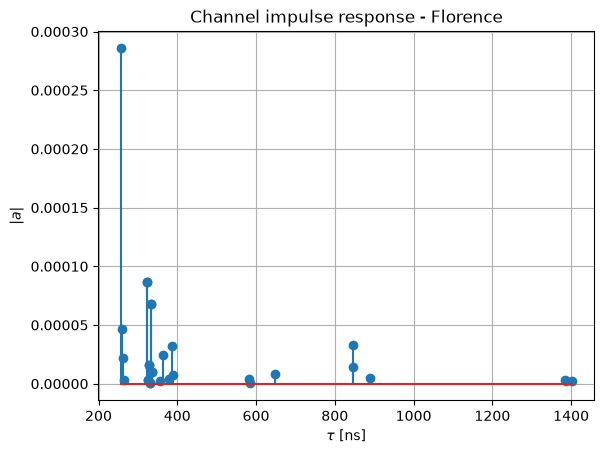

In [67]:
t = tau[0,0,0,0,:]/1e-9 # Scale to ns
a_abs = np.abs(a)[0,0,0,0,:,0]
a_max = np.max(a_abs)

# And plot the CIR
plt.figure()
plt.title("Channel impulse response - Florence")
plt.stem(t, a_abs)
plt.grid()
plt.xlabel(r"$\tau$ [ns]")
plt.ylabel(r"$|a|$");

We can obtain the channel frequency response in a similar manner. `paths,cfr` takes the cir (internally) and returns:
$$
\widehat{h}(f, t) = \sum_{i=0}^{M-1}a_i^\text{b}(t) e^{-j2\pi f \tau_{i}}
$$
Here it is evaluated on a uniformly spaced frequency grid spanning 20 MHz at about 3 GHz. 

Shape of h_freq: (1, 1, 1, 1, 1, 1024)


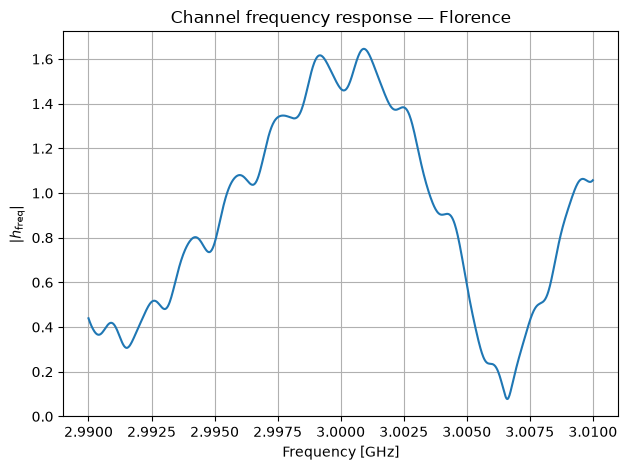

In [64]:
# Frequency sweep: 2.99 to 3.01 GHz, without OFDM parameters
bandwidth = 20e6  # Hz
num_frequencies = 1024
frequencies = np.linspace(-bandwidth/2, bandwidth/2, num_frequencies)
rf_frequencies = carrier_frequency + frequencies

h_freq = paths.cfr(frequencies=frequencies,
                   normalize=True,
                   normalize_delays=False,
                   out_type="numpy")
# Shape: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_time_steps, num_frequencies]
print("Shape of h_freq:", h_freq.shape)

plt.figure()
plt.plot(rf_frequencies/1e9, np.abs(h_freq[0,0,0,0,0,:]))
plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$|h_\mathrm{freq}|$")
plt.title("Channel frequency response — Florence")
plt.grid(True)
plt.tight_layout();


### CFR over time: static paths
Our aim here is to show the time variability of the channel under user mobility (whenever present).

First use the original `paths`, computed with stationary devices and objects.

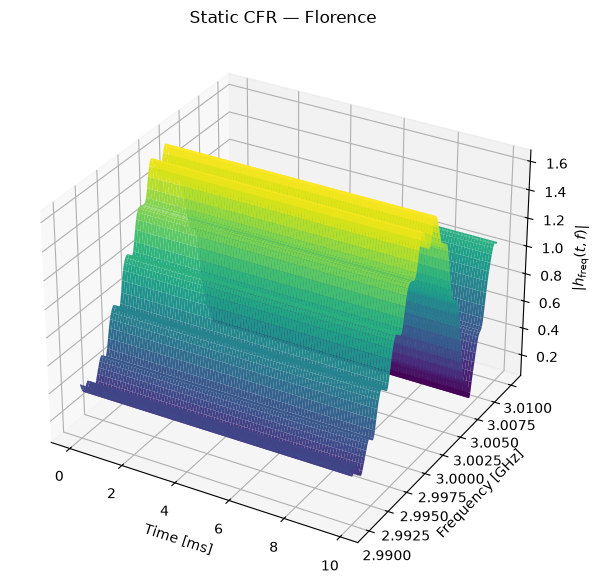

In [65]:
# Static reference: use the original paths without recomputing them.
num_time_steps = 100
sampling_frequency = 1e4  # Hz
h_freq_static = paths.cfr(frequencies=frequencies,
    sampling_frequency=sampling_frequency, num_time_steps=num_time_steps,
    normalize=True, normalize_delays=True, out_type="numpy")

time_ms = np.arange(num_time_steps)/sampling_frequency*1e3
time_grid, frequency_grid = np.meshgrid(time_ms, rf_frequencies/1e9, indexing="ij")

def plot_cfr_surface(h, title):
    fig = plt.figure(figsize=(10, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(time_grid, frequency_grid, np.abs(h[0,0,0,0,:,:]),
                    cmap="viridis", rcount=100, ccount=128)
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Frequency [GHz]")
    ax.set_zlabel(r"$|h_\mathrm{freq}(t,f)|$")
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

plot_cfr_surface(h_freq_static, "Static CFR — Florence")


### CFR over time: mobility paths

Every radio device and scene object has a velocity vector, used to compute path-specific Doppler shifts. Set the transmitter velocity to 10 m/s along x and recompute `paths_mob` using the same solver settings as the static case. The CFR then evolves according to these Doppler shifts, with geometry held at the traced snapshot. See the [Mobility tutorial](https://nvlabs.github.io/sionna/rt/tutorials/Mobility.html).

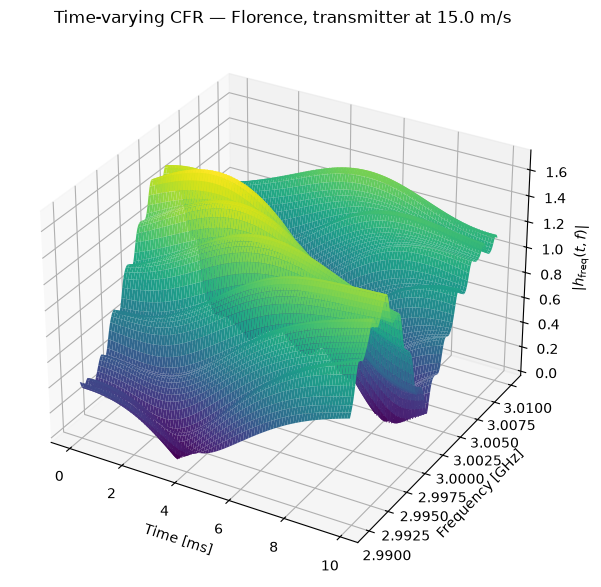

In [72]:
speed = [15, 0, 0]
speed_mag = np.linalg.norm(speed)
scene_florence.get("tx").velocity = speed
try:
    paths_mob = p_solver(scene=scene_florence,
        max_depth=5, los=True, specular_reflection=True,
        diffuse_reflection=False, refraction=True,
        synthetic_array=False, seed=41)
finally:
    # Restore the scene for repeatable static experiments.
    scene_florence.get("tx").velocity = [0, 0, 0]

h_freq_mob = paths_mob.cfr(frequencies=frequencies,
    sampling_frequency=sampling_frequency, num_time_steps=num_time_steps,
    normalize=True, normalize_delays=True, out_type="numpy")
plot_cfr_surface(h_freq_mob, f"Time-varying CFR — Florence, transmitter at {speed_mag} m/s")


## Transmission simulations

For link-level simulations in the time-domain, we often require the discrete baseband-equivalent channel impulse response or simply the channel taps.
These are obtained by sampling the ideally low-pass filtered channel impulse response at the desired sampling frequency. By default, it is assumed that sampling is performed at the Nyquist rate.

As the underlying sinc filter has an infinitely long response, the channel taps need to be truncated at a minimum and maximum value, i.e., `l_min` and `l_max`, respectively.

In [ ]:
taps = paths.taps(bandwidth=bandwidth, # Bandwidth to which the channel is low-pass filtered
                  l_min=-6,        # Smallest time lag
                  l_max=100,       # Largest time lag
                  sampling_frequency=None, # Sampling at Nyquist rate, i.e., 1/bandwidth
                  normalize=True,  # Normalize energy
                  normalize_delays=True,
                  out_type="numpy")
print("Shape of taps: ", taps.shape)

plt.figure()
plt.stem(np.arange(-6, 101), np.abs(taps)[0,0,0,0,0]);
plt.xlabel(r"Tap index $\ell$");
plt.ylabel(r"|$h[\ell]|$");
plt.title("Discrete channel taps");

## Summary

In this tutorial, you have learned the basics of Sionna RT. You now know how paths can be found in complex environments
and how the CIR, CFR, and taps can be derived from them, including static and Doppler-based time evolution.

There is one key feature of Sionna RT that was not discussed in this notebook: Automatic gradient computation.
Like most components of Sionna, also Sionna RT is differentiable with respect to most parameters, such as radio materials, scattering and atenna patterns, transmitter and receiver orientations, array geometries, positions, etc.

Please have a look at the [API documentation](https://nvlabs.github.io/sionna/rt/api/rt.html) of the various components and the other available [Tutorials](https://nvlabs.github.io/sionna/rt/tutorials.html) and [Developer Guides](https://nvlabs.github.io/sionna/rt/developer/developer.html).